# Data Preparation: election results (OpenCity)

**Input:** `interim/opencity_electiondata_{2014,2019,2024}.csv` from the data collection notebook.

**Output:** `clean/opencity_results_clean_2026-10-20.csv` (one row per real candidate per constituency per election), a data dictionary, a cleaning log and a before/after figure.

**States:** Bihar, Maharashtra, Uttar Pradesh, Tamil Nadu (207 seats in each election).

**How the notebook is organised:** every cleaning step prints a count before and after, and writes one line to the cleaning log. In the log, `count_before` and `count_after` are counts of rows or of problem cells, as said in the `note` column.

In [1]:
from pathlib import Path
import re
import difflib
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
# folders
project_dir = Path.cwd().parent
raw_dir = project_dir / "raw"
interim_dir = project_dir / "interim"
clean_dir = project_dir / "clean"
(clean_dir / "figures").mkdir(parents=True, exist_ok=True)

COLLECTION_DATE = "2026-10-20"

In [3]:
# load the prepared datasets
data = {
    year: pd.read_csv(interim_dir / f"opencity_electiondata_{year}.csv", low_memory=False)
    for year in [2014, 2019, 2024]
}

# cleaning log: one line per step
cleaning_log = []

def log_step(year, step, before, after, note=""):
    cleaning_log.append({
        "year": year, "step": step, "count_before": before,
        "count_after": after, "rows_affected": abs(before - after), "note": note
    })

### Step 1: keep the four states

The 2014 and 2019 files write state names with underscores (`Tamil_Nadu`), the 2024 file with spaces.

In [4]:
states = ["Bihar", "Maharashtra", "Uttar Pradesh", "Tamil Nadu"]

df_2014 = data[2014].rename(columns={"State_Name": "State"})
df_2019 = data[2019].rename(columns={"State_Name": "State"})
df_2024 = data[2024].rename(columns={"PC No": "Constituency_No", "PC Name": "Constituency_Name"})

# state names with an underscore, before and after
for year, df in [(2014, df_2014), (2019, df_2019)]:
    before = df["State"].str.contains("_").sum()
    df["State"] = df["State"].str.replace("_", " ")
    after = df["State"].str.contains("_").sum()
    log_step(year, "state names: underscore to space", before, after, "rows with an underscore in State")
    print(year, "rows with underscore before:", before, "after:", after)

selected = {}
for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    selected[year] = df[df["State"].isin(states)].copy()
    log_step(year, "keep four states", len(df), len(selected[year]), "rows")
    print(year, "rows before:", len(df), "after:", len(selected[year]))

df_2014, df_2019, df_2024 = selected[2014], selected[2019], selected[2024]

2014 rows with underscore before: 4010 after: 0
2019 rows with underscore before: 3447 after: 0
2014 rows before: 8843 after: 3868
2019 rows before: 8613 after: 3545
2024 rows before: 8902 after: 3626


### Step 2: remove by-elections

In the historical file `Poll_No` is 0 for the general election and 1 or more for by-elections. Four seat-years (two in 2014, two in 2019, among them Beed 2014 and Satara 2019) have vote shares that add up to 200, because the by-election was stored under the same constituency as the general election. Filtering on `Poll_No` fixes this and keeps all four seats. The 2024 file has no by-elections.

In [5]:
# constituency vote share totals before the filter (kept for the before/after figure)
seat_keys = ["State", "Constituency_No"]

totals_before = pd.concat([
    df.groupby(seat_keys)["Vote_Share_Percentage"].sum().rename("total").reset_index().assign(Year=year)
    for year, df in [(2014, df_2014), (2019, df_2019)]
])
print("seats with total vote share far from 100 (before):", ((totals_before["total"] - 100).abs() > 0.5).sum())
print(totals_before[(totals_before["total"] - 100).abs() > 0.5])

seats with total vote share far from 100 (before): 4
             State  Constituency_No   total  Year
78     Maharashtra               39  200.00  2014
147  Uttar Pradesh               21  199.99  2014
22           Bihar               23  199.99  2019
84     Maharashtra               45  200.00  2019


In [6]:
# keep only the general election
for year, df in [(2014, df_2014), (2019, df_2019)]:
    general = df[df["Poll_No"] == 0].copy()
    log_step(year, "drop by-election rows (Poll_No > 0)", len(df), len(general), "rows; fixes 4 seat-years whose vote shares added up to 200")
    print(year, "rows before:", len(df), "after:", len(general))
    if year == 2014:
        df_2014 = general
    else:
        df_2019 = general

totals_after = pd.concat([
    df.groupby(seat_keys)["Vote_Share_Percentage"].sum().rename("total").reset_index().assign(Year=year)
    for year, df in [(2014, df_2014), (2019, df_2019)]
])
print("seats with total vote share far from 100 (after):", ((totals_after["total"] - 100).abs() > 0.5).sum())

2014 rows before: 3868 after: 3844
2019 rows before: 3545 after: 3528
seats with total vote share far from 100 (after): 0


### Step 3: constituency names

**Matching rule:** the same seat in different years is matched by `State` + `Constituency_No`, never by name. Names are only for reading. Parliamentary seats of these four states were not redrawn between 2014 and 2024, which the seat counts below confirm (Bihar 40, Maharashtra 48, Uttar Pradesh 80, Tamil Nadu 39).

In [7]:
def clean_name(name):
    name = re.sub(r"\((SC|ST)\)", "", str(name), flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", name).strip().upper()

for df in [df_2014, df_2019, df_2024]:
    df["Constituency_Name"] = df["Constituency_Name"].map(clean_name)

# seat counts: exactly 207
expected = {"Bihar": 40, "Maharashtra": 48, "Uttar Pradesh": 80, "Tamil Nadu": 39}
for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    seats = df.groupby("State")["Constituency_No"].nunique().to_dict()
    assert seats == expected, f"seat counts wrong in {year}"
print("seat counts OK in all three years:", expected)

seat counts OK in all three years: {'Bihar': 40, 'Maharashtra': 48, 'Uttar Pradesh': 80, 'Tamil Nadu': 39}


In [8]:
# the same seat is spelled differently in some years
names = pd.concat({
    year: df.drop_duplicates(seat_keys).set_index(seat_keys)["Constituency_Name"]
    for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]
}, axis=1)

different = names[names.nunique(axis=1) > 1]
print("seats with more than one spelling:", len(different))
print(different.to_string())

seats with more than one spelling: 9
                                                 2014                    2019                   2024
State         Constituency_No                                                                       
Bihar         31                          PATALIPUTRA             PATALIPUTRA             PATLIPUTRA
Maharashtra   11                   BHANDARA - GONDIYA      BHANDARA - GONDIYA       BHANDARA GONDIYA
              12                    GADCHIROLI-CHIMUR       GADCHIROLI-CHIMUR    GADCHIROLI - CHIMUR
              14                      YAVATMAL-WASHIM         YAVATMAL-WASHIM       YAVATMAL- WASHIM
              37                           AHMADNAGAR              AHMADNAGAR             AHMEDNAGAR
              46               RATNAGIRI - SINDHUDURG  RATNAGIRI - SINDHUDURG  RATNAGIRI- SINDHUDURG
              48                          HATKANANGLE             HATKANANGLE           HATKANANGALE
Tamil Nadu    1                           THIRUVALLUR 

In [9]:
# one spelling per seat: the 2019 spelling (TCPD), because two of three files agree most often
canonical = names[2019]

pairs_before = sum(df[["State", "Constituency_Name"]].drop_duplicates().shape[0] for df in [df_2014, df_2019, df_2024])

for df in [df_2014, df_2019, df_2024]:
    df["Constituency_Name"] = df.set_index(seat_keys).index.map(canonical).values

pairs_after = pd.concat([df[["State", "Constituency_Name"]] for df in [df_2014, df_2019, df_2024]]).drop_duplicates().shape[0]

log_step("all", "one name per seat", pairs_before, pairs_after, "distinct (State, name) pairs over three years; 207 seats expected")
print("distinct (State, name) pairs before:", pairs_before, "after:", pairs_after)
assert pairs_after == 207

distinct (State, name) pairs before: 621 after: 207


### Step 4: numbers stored as text (2024)

In the 2024 file votes and vote share are text, and postal votes use `-` for zero. We check that EVM + postal = total on the full file (all states), then convert.

In [10]:
raw_2024 = data[2024]

print("postal votes written as '-':", (raw_2024["Postal Votes"] == "-").sum())
print("EVM votes written as '-':", (raw_2024["EVM Votes"] == "-").sum())

votes = raw_2024[["EVM Votes", "Postal Votes", "Total Votes"]].replace("-", "0").apply(pd.to_numeric, errors="coerce")
complete = votes.notna().all(axis=1)
matches = votes["EVM Votes"] + votes["Postal Votes"] == votes["Total Votes"]

print("Rows checked (all states):", complete.sum())
print("Rows where EVM + Postal = Total:", (complete & matches).sum())
print("Rows where EVM + Postal != Total:", (complete & ~matches).sum())

postal votes written as '-': 578
EVM votes written as '-': 1
Rows checked (all states): 8902
Rows where EVM + Postal = Total: 8902
Rows where EVM + Postal != Total: 0


In [11]:
# convert to numbers and count text cells before and after
for col in ["Total Votes", "Vote Share"]:
    not_numeric_before = df_2024[col].map(lambda v: isinstance(v, str)).sum()
    df_2024[col] = pd.to_numeric(df_2024[col].replace("-", "0"))
    not_numeric_after = df_2024[col].map(lambda v: isinstance(v, str)).sum()
    log_step(2024, f"{col}: text to number", not_numeric_before, not_numeric_after, "cells stored as text")
    print(col, "text cells before:", not_numeric_before, "after:", not_numeric_after)

df_2024["Votes"] = df_2024["Total Votes"].astype(int)
df_2024["Vote_Share_Percentage"] = df_2024["Vote Share"].astype(float)

# votes and vote shares: range and total checks for all years
for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    share = df["Vote_Share_Percentage"]
    totals = df.groupby(seat_keys)["Vote_Share_Percentage"].sum()
    print(f"{year}: missing {share.isna().sum()}, below 0: {(share < 0).sum()}, above 100: {(share > 100).sum()}, "
          f"seat totals outside 99.5-100.5: {((totals - 100).abs() > 0.5).sum()}")

Total Votes text cells before: 3626 after: 0
Vote Share text cells before: 3626 after: 0
2014: missing 0, below 0: 0, above 100: 0, seat totals outside 99.5-100.5: 0
2019: missing 0, below 0: 0, above 100: 0, seat totals outside 99.5-100.5: 0
2024: missing 0, below 0: 0, above 100: 0, seat totals outside 99.5-100.5: 0


### Step 5: text inconsistencies in names and parties

Candidate names come in many forms: mixed case, dots (`KUMAR.P`), the `SURNAME, INITIALS` form used in Tamil Nadu (`Balaganapathy, V. Pon`), double spaces and titles (`DR`, `ADV`). Party names in 2024 have double spaces (`Janata Dal  (United)`).

**Rule:** upper case, dots and commas become spaces, other symbols removed, spaces collapsed, titles removed. The word order is kept for display. For matching, a separate key is made from the words sorted alphabetically, so `BALAGANAPATHY V PON` and `V PON BALAGANAPATHY` get the same key.

In [12]:
TITLES = {"DR", "ADV", "ADVOCATE", "SHRI", "SRI", "SMT", "SHRIMATI", "PROF", "PROFESSOR", "CAPT", "COL", "MR", "MRS", "MS", "SHREE"}

def clean_candidate(name):
    text = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper().replace(".", " ").replace(",", " "))
    tokens = [t for t in text.split() if t not in TITLES]
    return " ".join(tokens)

def name_key(name):
    return " ".join(sorted(name.split()))

def name_problems(series):
    s = series.astype(str)
    return {
        "not upper case": int((s != s.str.upper()).sum()),
        "has dot": int(s.str.contains(r"\.").sum()),
        "has comma": int(s.str.contains(",").sum()),
        "double space": int(s.str.contains(r"\s\s").sum()),
        "has title": int(s.map(lambda x: any(t in TITLES for t in re.sub(r"[^A-Za-z ]", " ", x).upper().split())).sum()),
    }

before_total = {}
for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    problems_before = name_problems(df["Candidate"])
    df["Candidate"] = df["Candidate"].map(clean_candidate)
    df["Candidate_Key"] = df["Candidate"].map(name_key)
    problems_after = name_problems(df["Candidate"])

    for kind in problems_before:
        log_step(year, f"candidate names: {kind}", problems_before[kind], problems_after[kind], "names with this problem")
    print(f"{year} before: {problems_before}")
    print(f"{year} after:  {problems_after}")

2014 before: {'not upper case': 208, 'has dot': 861, 'has comma': 186, 'double space': 76, 'has title': 159}
2014 after:  {'not upper case': 0, 'has dot': 0, 'has comma': 0, 'double space': 0, 'has title': 0}
2019 before: {'not upper case': 1632, 'has dot': 750, 'has comma': 160, 'double space': 0, 'has title': 168}
2019 after:  {'not upper case': 0, 'has dot': 0, 'has comma': 0, 'double space': 0, 'has title': 0}
2024 before: {'not upper case': 17, 'has dot': 448, 'has comma': 73, 'double space': 50, 'has title': 165}
2024 after:  {'not upper case': 0, 'has dot': 0, 'has comma': 0, 'double space': 0, 'has title': 0}


In [13]:
# party names: spaces
def tidy_spaces(series):
    return series.astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

before = df_2024["Party"].str.contains(r"\s\s").sum()
df_2024["Party"] = tidy_spaces(df_2024["Party"])
after = df_2024["Party"].str.contains(r"\s\s").sum()
log_step(2024, "party names: double spaces", before, after, "names with double spaces")
print("party names with double spaces before:", before, "after:", after)

party names with double spaces before: 88 after: 0


### Step 6: NOTA, position and margin

`None of the Above` (NOTA) is stored as a candidate in all three files under different names. It cannot win, so it is flagged and left out of the ranking. Its votes stay in the seat total.

The published `Position` of 2014 and 2019 gives NOTA a rank like a candidate, which pushes real candidates one place down. Position and margin are therefore recomputed from votes, with the same rule for all three years.

In [14]:
for df in [df_2014, df_2019, df_2024]:
    df["Is_NOTA"] = (
        df["Party"].isin(["NOTA", "None of the Above"])
        | df["Candidate"].isin(["NOTA", "NONE OF THE ABOVE"])
    )

for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    print(year, "NOTA rows:", df["Is_NOTA"].sum(), "| names:", sorted(df.loc[df["Is_NOTA"], "Candidate"].unique()))

# 2019: one seat has no NOTA row
print("2019 seats without a NOTA row:", 207 - df_2019["Is_NOTA"].sum())

2014 NOTA rows: 207 | names: ['NONE OF THE ABOVE']
2019 NOTA rows: 206 | names: ['NOTA']
2024 NOTA rows: 207 | names: ['NOTA']
2019 seats without a NOTA row: 1


In [15]:
position_fix = {}

for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    real_votes = df["Votes"].where(~df["Is_NOTA"])
    new_position = real_votes.groupby([df[k] for k in seat_keys]).rank(method="min", ascending=False)

    if "Position" in df.columns:
        wrong = ((df["Position"] != new_position) & ~df["Is_NOTA"]).sum()
    else:
        wrong = 0
    position_fix[year] = wrong
    df["Position"] = new_position

    log_step(year, "position recomputed without NOTA", wrong, 0, "real candidates whose published position was wrong")
    print(year, "real candidates with a wrong published position:", wrong, "of", (~df["Is_NOTA"]).sum())

for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    winners = df[df["Position"] == 1].groupby(seat_keys).size()
    assert len(winners) == 207 and (winners == 1).all()
print("exactly one winner in every seat, every year")

2014 real candidates with a wrong published position: 2446 of 3637
2019 real candidates with a wrong published position: 2456 of 3322
2024 real candidates with a wrong published position: 0 of 3419
exactly one winner in every seat, every year


In [16]:
# winner flag, seat valid votes, and winning margin (votes between 1st and 2nd)
def add_seat_columns(df):
    df = df.copy()
    df["Winner"] = df["Position"] == 1
    df["Seat_Valid_Votes"] = df.groupby(seat_keys)["Votes"].transform("sum")

    first = df[df["Position"] == 1].set_index(seat_keys)["Votes"]
    second = df[df["Position"] == 2].set_index(seat_keys)["Votes"]
    margin = (first - second).rename("Margin")

    df = df.drop(columns=[c for c in ["Margin"] if c in df.columns])
    df = df.merge(margin, left_on=seat_keys, right_index=True, how="left")
    df["Seat_Candidates"] = df.groupby(seat_keys)["Is_NOTA"].transform(lambda s: (~s).sum())
    return df

df_2014, df_2019, df_2024 = [add_seat_columns(df) for df in [df_2014, df_2019, df_2024]]

for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    print(year, "margin min:", df["Margin"].min(), "| median:", df["Margin"].median(), "| missing:", df["Margin"].isna().sum())

2014 margin min: 1632.0 | median: 156756.0 | missing: 0
2019 margin min: 181.0 | median: 185720.0 | missing: 0
2024 margin min: 48 | median: 112482.0 | missing: 0


### Step 7: missing values

First the pattern: which columns are empty, in which years.

In [17]:
# columns that only the historical file has; 2024 does not have them at all
for col in ["Sex", "Constituency_Type", "Incumbent", "Turncoat", "Electors"]:
    df_2024[col] = np.nan
df_2024["Year"] = 2024

check_cols = ["Sex", "Constituency_Type", "Incumbent", "Turncoat", "Electors", "Votes", "Vote_Share_Percentage", "Party"]
missing = pd.concat({
    year: df[check_cols].isna().sum()
    for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]
}, axis=1)
missing.loc["rows"] = [len(df_2014), len(df_2019), len(df_2024)]
missing

,2014,2019,2024
Sex,0,206,3626
Constituency_Type,0,0,3626
Incumbent,207,206,3626
Turncoat,207,206,3626
Electors,0,0,3626
Votes,0,0,0
Vote_Share_Percentage,0,0,0
Party,0,0,0
rows,3844,3528,3626


In [18]:
# in 2014 and 2019: is the missing pattern linked to NOTA rows?
historic = pd.concat([df_2014, df_2019], ignore_index=True)

for col in ["Sex", "Incumbent", "Turncoat"]:
    table = pd.crosstab(historic["Is_NOTA"], historic[col].isna())
    chi2, p, _, _ = stats.chi2_contingency(table)
    print(f"\n{col}: missing vs NOTA row")
    print(table.to_string())
    print(f"chi-square = {chi2:.1f}, p = {p:.2e}")

# is any real candidate row missing a value?
real = historic[~historic["Is_NOTA"]]
print("\nmissing cells in real candidate rows (2014, 2019):")
print(real[["Sex", "Constituency_Type", "Incumbent", "Turncoat", "Electors"]].isna().sum().to_dict())


Sex: missing vs NOTA row
Sex      False  True 
Is_NOTA              
False     6959      0
True       207    206
chi-square = 3552.5, p = 0.00e+00

Incumbent: missing vs NOTA row
Incumbent  False  True 
Is_NOTA                
False       6959      0
True           0    413
chi-square = 7353.1, p = 0.00e+00

Turncoat: missing vs NOTA row
Turncoat  False  True 
Is_NOTA               
False      6959      0
True          0    413
chi-square = 7353.1, p = 0.00e+00

missing cells in real candidate rows (2014, 2019):
{'Sex': 0, 'Constituency_Type': 0, 'Incumbent': 0, 'Turncoat': 0, 'Electors': 0}


**Mechanism.**
- *2014 and 2019:* the only missing cells are in the NOTA rows. `Incumbent` and `Turncoat` are missing in every NOTA row and in no real candidate row. `Sex` is missing in the 2019 NOTA rows, while in 2014 the NOTA rows carry the word `NOTA` in `Sex`, which is another sign that the field does not apply. The chi-square tests show the link is complete (p near 0). NOTA is not a person, so these fields do not apply. This is missing **by definition**, not MCAR, MAR or MNAR in the usual sense (the cause is known and written into the data design).
- *2024:* `Sex`, `Constituency_Type`, `Incumbent`, `Turncoat` and `Electors` are missing for every row because the ECI file does not have these columns. This is **structural**: the missingness depends on the source, which is the same for the whole year, so it is not random.

**Handling:**
- NOTA rows: deleted from the candidate table (NOTA votes stay inside `Seat_Valid_Votes`). Imputing a sex or incumbency for NOTA would be meaningless.
- `Constituency_Type` 2024: imputed from 2019 by seat number. This is safe only if the type never changed between 2014 and 2019, which is checked below.
- `Incumbent` 2024: derived from the 2019 winners by matching people across years (Step 9), after testing the same method on 2019.
- `Sex`, `Turncoat`, `Electors` 2024: left missing. They cannot be derived honestly, and the analysis does not need them. Deleting the three years' rows would lose all of 2024, so the columns are kept with missing values and marked in the data dictionary.

In [19]:
# constituency type must be the same in 2014 and 2019 for every seat, otherwise copying it to 2024 is not safe
types = pd.concat([
    df.drop_duplicates(seat_keys).set_index(seat_keys)["Constituency_Type"].rename(year)
    for year, df in [(2014, df_2014), (2019, df_2019)]
], axis=1)
print("seats where type differs between 2014 and 2019:", (types[2014] != types[2019]).sum())
print("types in 2019:", types[2019].value_counts().to_dict())

before = df_2024["Constituency_Type"].isna().sum()
df_2024["Constituency_Type"] = df_2024.set_index(seat_keys).index.map(types[2019]).values
after = df_2024["Constituency_Type"].isna().sum()
log_step(2024, "constituency type imputed from 2019", before, after, "missing cells")
print("2024 missing constituency type before:", before, "after:", after)

seats where type differs between 2014 and 2019: 0
types in 2019: {'GEN': 168, 'SC': 35, 'ST': 4}
2024 missing constituency type before: 3626 after: 0


### Step 8: party codes

2014 and 2019 use short codes (BJP, INC). 2024 uses full names. The main parties of the four states are mapped to the short codes. Small parties in 2024 become `OTHER`, which is enough because the analysis only separates main parties, independents and the rest.

In [20]:
party_map_2024 = {
    "Independent": "IND", "None of the Above": "NOTA",
    "Bharatiya Janata Party": "BJP", "Indian National Congress": "INC",
    "Bahujan Samaj Party": "BSP", "Samajwadi Party": "SP",
    "Rashtriya Janata Dal": "RJD", "Janata Dal (United)": "JD(U)",
    "Dravida Munnetra Kazhagam": "DMK",
    "All India Anna Dravida Munnetra Kazhagam": "ADMK",
    "Shiv Sena": "SHS", "Shiv Sena (Uddhav Balasaheb Thackrey)": "SHS(UBT)",
    "Nationalist Congress Party": "NCP",
    "Nationalist Congress Party – Sharadchandra Pawar": "NCP(SP)",
    "Naam Tamilar Katchi": "NTK", "Communist Party of India": "CPI",
    "Communist Party of India (Marxist)": "CPM",
    "Communist Party of India (Marxist-Leninist) (Liberation)": "CPI(ML)(L)",
    "Lok Janshakti Party(Ram Vilas)": "LJP(RV)", "Vanchit Bahujan Aaghadi": "VBA",
    "All India Majlis-E-Ittehadul Muslimeen": "AIMIM", "Pattali Makkal Katchi": "PMK",
    "Desiya Murpokku Dravida Kazhagam": "DMDK", "Viduthalai Chiruthaigal Katchi": "VCK",
    "Marumalarchi Dravida Munnetra Kazhagam": "MDMK", "Rashtriya Lok Dal": "RLD",
    "Hindustani Awam Morcha (Secular)": "HAMS",
}

df_2024["Party_Full"] = df_2024["Party"]
df_2024["Party"] = df_2024["Party_Full"].map(party_map_2024).fillna("OTHER")
print("2024 rows mapped to OTHER:", (df_2024["Party"] == "OTHER").sum(), "of", len(df_2024))

for df in [df_2014, df_2019]:
    df["Party_Full"] = df["Party"]
    df["Party"] = df["Party"].replace({"CPIM": "CPM"})

main_parties = ["BJP", "INC", "SP", "BSP", "RJD", "JD(U)", "DMK", "ADMK", "SHS", "NCP"]

for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    df["Party_Group"] = np.select(
        [df["Party"].isin(main_parties), df["Party"] == "IND", df["Party"] == "NOTA"],
        ["Main party", "Independent", "NOTA"], default="Other party"
    )
    print(year, df["Party_Group"].value_counts().to_dict())

2024 rows mapped to OTHER: 983 of 3626
2014 {'Independent': 1503, 'Other party': 1302, 'Main party': 832, 'NOTA': 207}
2019 {'Independent': 1474, 'Other party': 1262, 'Main party': 586, 'NOTA': 206}
2024 {'Independent': 1698, 'Other party': 1147, 'Main party': 574, 'NOTA': 207}


### Step 9: duplicates

**Exact duplicates:** the same row twice.

**Namesakes inside one seat:** the same name twice in one seat and year. These are often *different people*: a candidate files with the same name as a main-party candidate (a known tactic to split votes). They are kept, flagged, and never merged.

**Same person in different years (across sources):** a person who contested in 2014, 2019 and 2024 appears three times, under spellings that differ between the TCPD files and the ECI file. A `Person_ID` is given with this rule, applied to two elections at a time, using only rows not yet matched:

1. *Same seat, same name key:* match. If two rows share the key, prefer the one with the same party.
2. *Same seat, similar name key:* match when `difflib` similarity of the keys is at least 0.95, or when both rows have the same named party (not `IND` or `OTHER`) and share at least two name words of three or more letters that are not very common words (`KUMAR`, `SINGH`, ...), for example `GOPAL CHINAYYA SHETTY` and `GOPAL SHETTY` (one-to-one, best first).

Rules 1 and 2 have a guard: if either row is an independent, the name must have at least three words. Short names shared with an independent are common names or vote-splitting namesakes (in a trial against TCPD's `Contested` column, such links were wrong about one time in three).
3. *Different seat, same state, same name key:* match only if the party is the same, the party is not `IND`, and the key is unique in both years. This catches people who changed seat, and avoids common names.

The rule is tested at the end of this step against columns published by TCPD.

In [21]:
# exact duplicate rows
for year, df in [(2014, df_2014), (2019, df_2019), (2024, df_2024)]:
    exact = df.duplicated().sum()
    log_step(year, "exact duplicate rows", exact, 0, "rows")
    print(year, "exact duplicate rows:", exact)

# namesakes inside one seat
all_years = pd.concat([df_2014, df_2019, df_2024], ignore_index=True)
real_rows = all_years[~all_years["Is_NOTA"]].copy()
real_rows["Namesake_In_Seat"] = real_rows.duplicated(["Year", "State", "Constituency_No", "Candidate_Key"], keep=False)

print("\nrows that share a name with another candidate in the same seat:", real_rows["Namesake_In_Seat"].sum())
print(real_rows[real_rows["Namesake_In_Seat"]].groupby("Year").size().to_dict())
print(real_rows[real_rows["Namesake_In_Seat"] & (real_rows["Year"] == 2024)][["Constituency_Name", "Candidate", "Party", "Votes"]].head(8).to_string())

2014 exact duplicate rows: 0
2019 exact duplicate rows: 0
2024 exact duplicate rows: 0

rows that share a name with another candidate in the same seat: 58
{2014: 18, 2019: 18, 2024: 22}
     Constituency_Name           Candidate       Party     Votes
7749           NALANDA         MUNNA KUMAR       OTHER    1949.0
7750           NALANDA         MUNNA KUMAR       OTHER    1880.0
7837           KARAKAT      RAJA RAM SINGH  CPI(ML)(L)  380581.0
7841           KARAKAT      RAJA RAM SINGH         IND   21383.0
7852         JAHANABAD  CHANDESHWAR PRASAD       JD(U)  300444.0
7860         JAHANABAD  CHANDESHWAR PRASAD         IND    5378.0
9173   CHENNAI CENTRAL     B PARTHASARATHY        DMDK   72016.0
9184   CHENNAI CENTRAL     S SATHISH KUMAR         IND     527.0


In [22]:
# one-to-one matching of one election (new) to an earlier one (old)
# very common name words do not count as evidence
COMMON_WORDS = {"KUMAR", "SINGH", "PRASAD", "DEVI", "YADAV", "KUMARI", "SHARMA", "KHAN", "MOHAMMAD", "MOHD", "LAL", "KAUR",
                "NATH", "REDDY", "PATIL", "KUMARAN", "PANDEY", "VERMA", "GUPTA", "MISHRA", "SAHU", "PASWAN", "RAJ", "RAJA", "ALIAS"}

def allowed(nrow, orow):
    # a name shared with an independent is weak evidence: common names, and namesakes who stand to split votes
    weak = nrow["Party"] == "IND" or orow["Party"] == "IND"
    return (not weak) or len(nrow["Candidate_Key"].split()) >= 3

def match_years(old, new, used_old):
    pairs = []
    taken_new = set()

    # rule 1: same seat, same key (same party first)
    for (state, seat), new_seat in new.groupby(seat_keys):
        old_seat = old[(old["State"] == state) & (old["Constituency_No"] == seat) & ~old.index.isin(used_old)]
        for key, new_rows in new_seat.groupby("Candidate_Key"):
            old_rows = old_seat[old_seat["Candidate_Key"] == key]
            for i, nrow in new_rows.sort_values("Votes", ascending=False).iterrows():
                if old_rows.empty:
                    break
                old_rows = old_rows[[allowed(nrow, orow) for _, orow in old_rows.iterrows()]]
                if old_rows.empty:
                    continue
                same_party = old_rows[old_rows["Party"] == nrow["Party"]]
                pick = same_party.index[0] if len(same_party) else old_rows.index[0]
                pairs.append((pick, i, 1))
                taken_new.add(i)
                used_old = used_old | {pick}
                old_rows = old_rows.drop(pick)

    # rule 2: same seat, similar key
    for (state, seat), new_seat in new.groupby(seat_keys):
        old_seat = old[(old["State"] == state) & (old["Constituency_No"] == seat) & ~old.index.isin(used_old)]
        scores = []
        for i, nrow in new_seat[~new_seat.index.isin(taken_new)].iterrows():
            for j, orow in old_seat.iterrows():
                ratio = difflib.SequenceMatcher(None, nrow["Candidate_Key"], orow["Candidate_Key"]).ratio()
                shared_word = (nrow["Party"] == orow["Party"] and nrow["Party"] not in ["IND", "OTHER"] and
                               sum(len(w) >= 3 and w not in COMMON_WORDS for w in set(nrow["Candidate_Key"].split()) & set(orow["Candidate_Key"].split())) >= 2)
                if (ratio >= 0.95 and allowed(nrow, orow)) or shared_word:
                    scores.append((max(ratio, 0.9), j, i))
        for ratio, j, i in sorted(scores, reverse=True):
            if j in used_old or i in taken_new:
                continue
            pairs.append((j, i, 2))
            taken_new.add(i)
            used_old = used_old | {j}

    # rule 3: same state, same key, same non-independent party, unique key
    for state in new["State"].unique():
        old_state = old[(old["State"] == state) & ~old.index.isin(used_old) & (old["Party"] != "IND")]
        new_state = new[(new["State"] == state) & ~new.index.isin(taken_new) & (new["Party"] != "IND")]
        old_count = old_state["Candidate_Key"].value_counts()
        new_count = new_state["Candidate_Key"].value_counts()
        for i, nrow in new_state.iterrows():
            key = nrow["Candidate_Key"]
            if len(key.split()) < 2 or old_count.get(key, 0) != 1 or new_count.get(key, 0) != 1:
                continue
            candidates = old_state[(old_state["Candidate_Key"] == key) & (old_state["Party"] == nrow["Party"])]
            if len(candidates) == 1 and candidates.index[0] not in used_old:
                pairs.append((candidates.index[0], i, 3))
                taken_new.add(i)
                used_old = used_old | {candidates.index[0]}

    return pairs

In [23]:
# give a Person_ID to every real candidate row
real_rows = real_rows.reset_index(drop=True)
real_rows["Person_ID"] = np.arange(len(real_rows))
real_rows["Match_Rule"] = 0

by_year = {y: real_rows[real_rows["Year"] == y] for y in [2014, 2019, 2024]}

def link(old_year, new_year):
    old = real_rows[real_rows["Year"] == old_year]
    new = real_rows[(real_rows["Year"] == new_year)]
    # only rows not yet linked to an earlier year can be linked now
    new = new[new["Person_ID"] == new.index.to_series()]
    # old rows already used by a later link are not offered again
    already = set(real_rows.index[(real_rows["Year"] == old_year) & real_rows["Person_ID"].isin(
        real_rows.loc[real_rows["Year"] == new_year, "Person_ID"][real_rows.loc[real_rows["Year"] == new_year, "Person_ID"] != real_rows.loc[real_rows["Year"] == new_year].index.to_series()])])
    pairs = match_years(old, new, already)
    for j, i, rule in pairs:
        real_rows.loc[i, "Person_ID"] = real_rows.loc[j, "Person_ID"]
        real_rows.loc[i, "Match_Rule"] = rule
    return pairs

pairs_1419 = link(2014, 2019)
pairs_1924 = link(2019, 2024)
pairs_1424 = link(2014, 2024)

for name, pairs in [("2014 -> 2019", pairs_1419), ("2019 -> 2024", pairs_1924), ("2014 -> 2024 (skipped 2019)", pairs_1424)]:
    print(name, "links:", len(pairs), "| by rule:", pd.Series([p[2] for p in pairs]).value_counts().sort_index().to_dict())

# how many elections does each person appear in
elections = real_rows.groupby("Person_ID")["Year"].nunique()
print("\npeople by number of elections contested (in these four states):", elections.value_counts().sort_index().to_dict())
assert real_rows.duplicated(["Person_ID", "Year"]).sum() == 0, "a person appears twice in one election"

2014 -> 2019 links: 322 | by rule: {1: 243, 2: 48, 3: 31}
2019 -> 2024 links: 326 | by rule: {1: 275, 2: 40, 3: 11}
2014 -> 2024 (skipped 2019) links: 54 | by rule: {1: 40, 2: 11, 3: 3}

people by number of elections contested (in these four states): {1: 9113, 2: 424, 3: 139}


In [24]:
# test the matching against columns published by TCPD for 2019 (Recontest: contested the previous election)
published = data[2019]
published = published[(published["State_Name"].isin(["Bihar", "Maharashtra", "Uttar_Pradesh", "Tamil_Nadu"])) & (published["Poll_No"] == 0)]
published_flag = published.assign(
    State=published["State_Name"].str.replace("_", " "),
    Candidate=published["Candidate"].map(clean_candidate)
)[["State", "Constituency_No", "Candidate", "Party", "Recontest", "Incumbent"]]

check = real_rows[real_rows["Year"] == 2019].merge(
    published_flag.rename(columns={"Party": "Party_p", "Recontest": "Recontest_p", "Incumbent": "Incumbent_p"}),
    on=["State", "Constituency_No", "Candidate"], how="left"
)
check = check.drop_duplicates(["State", "Constituency_No", "Candidate", "Party"])
check["linked_to_2014"] = check["Person_ID"].isin(real_rows.loc[real_rows["Year"] == 2014, "Person_ID"])

# the TCPD column 'Contested' travels with the rows (number of elections the person has contested, any state)
linked = check[check["linked_to_2014"]]
print("2019 candidates linked to a 2014 row by my rule:", len(linked))
print("   of these, TCPD says it was their first contest (a certainly wrong link):", (linked["Contested"] == 1).sum())
print(f"   precision (at least): {(linked['Contested'] > 1).mean():.3f}")

has_earlier = check["Contested"] > 1
print("2019 candidates TCPD says contested before (anywhere in India):", has_earlier.sum())
print("   of these, linked to a 2014 row in the four states:", (has_earlier & check["linked_to_2014"]).sum())

2019 candidates linked to a 2014 row by my rule: 322
   of these, TCPD says it was their first contest (a certainly wrong link): 17
   precision (at least): 0.947
2019 candidates TCPD says contested before (anywhere in India): 535
   of these, linked to a 2014 row in the four states: 305


**Reading the test.** TCPD's `Contested` counts how many elections a person has contested, in any state. A link to an earlier election is wrong when it says 1 (first contest), so that count is an estimate of the error. The estimate is on the cautious side: TCPD's own linking of people is not perfect (for example, it gives `Contested` = 1 to the same Nanded candidate in 2019 who stood there for the same party in 2014), so some "wrong" links are right. Our files hold four states only, so some true re-contestants cannot be linked (they contested elsewhere before); that explains the missing recall and is accepted.

### Step 10: incumbent in 2024

TCPD publishes `Incumbent` for 2014 and 2019 only. For 2024 it is derived: a candidate is an incumbent if the same person *won* in 2019, or won a by-election after that (the file holds by-elections only up to 2021, so later ones are missed). The method is first run on 2019 (2014 winners and by-election winners of that term) and compared with the published column, to see how far it can be trusted.

In [25]:
winners_2014 = set(real_rows.loc[(real_rows["Year"] == 2014) & real_rows["Winner"], "Person_ID"])
winners_2019 = set(real_rows.loc[(real_rows["Year"] == 2019) & real_rows["Winner"], "Person_ID"])

# sitting MPs also include winners of by-elections held during the term (file has them with Poll_No > 0, up to 2021)
hist = pd.read_csv(interim_dir / "opencity_byelections_2014_onwards.csv", low_memory=False)
hist = hist[hist["State_Name"].isin(["Bihar", "Maharashtra", "Uttar_Pradesh", "Tamil_Nadu"]) & (hist["Poll_No"] > 0) & (hist["Position"] == 1)]
hist["State"] = hist["State_Name"].str.replace("_", " ")
hist["Candidate_Key"] = hist["Candidate"].map(clean_candidate).map(name_key)

# term of the 2014 parliament: after the 2014 election and before April 2019; term of 2019: after June 2019
term_2014 = hist[((hist["Year"] == 2014) & (hist["month"] >= 6)) | hist["Year"].between(2015, 2018) | ((hist["Year"] == 2019) & (hist["month"] < 4))]
term_2019 = hist[((hist["Year"] == 2019) & (hist["month"] >= 6)) | hist["Year"].between(2020, 2021)]
print("by-election winners in the 2014 term:", len(term_2014), "| in the 2019 term (file ends in 2021):", len(term_2019))

bypoll_keys = {2019: set(zip(term_2014["State"], term_2014["Candidate_Key"])), 2024: set(zip(term_2019["State"], term_2019["Candidate_Key"]))}

# test on 2019
test = check.copy()
test["derived"] = test["Person_ID"].isin(winners_2014) | pd.Series([(a, b) in bypoll_keys[2019] for a, b in zip(test["State"], test["Candidate_Key"])], index=test.index)
test["published"] = test["Incumbent_p"].astype(str) == "True"

print("2019: derived incumbent vs published incumbent")
print(pd.crosstab(test["published"], test["derived"], rownames=["published"], colnames=["derived"]).to_string())
agree = (test["published"] == test["derived"]).mean()
print(f"agreement: {agree:.4f}")

by-election winners in the 2014 term: 6 | in the 2019 term (file ends in 2021): 2
2019: derived incumbent vs published incumbent
derived    False  True 
published              
False       3185      3
True          21    111
agreement: 0.9928


In [26]:
# apply to 2024
real_rows["Incumbent_Source"] = np.where(real_rows["Year"] == 2024, "derived", "published")
mask_2024 = real_rows["Year"] == 2024
real_rows.loc[mask_2024, "Incumbent"] = (
    real_rows.loc[mask_2024, "Person_ID"].isin(winners_2019)
    | pd.Series([(a, b) in bypoll_keys[2024] for a, b in zip(real_rows.loc[mask_2024, "State"], real_rows.loc[mask_2024, "Candidate_Key"])], index=real_rows.index[mask_2024])
)

before = real_rows.loc[mask_2024, "Incumbent"].isna().sum()
log_step(2024, "incumbent derived from 2019 winners", before, real_rows.loc[mask_2024, "Incumbent"].isna().sum(), "missing cells (all 2024 rows had no value)")
print("2024 incumbents found:", real_rows.loc[mask_2024, "Incumbent"].sum(), "of", mask_2024.sum())
print("2019 winners (four states):", len(winners_2019))

2024 incumbents found: 124 of 3419
2019 winners (four states): 207


### Step 11: outliers

Votes are very skewed (winners get 100 times the votes of independents), so a plain rule on all votes would flag every winner. Two checks are used instead.

**Candidate level:** `log10(Votes)`, compared inside a group of the same year and the same role (winner, runner-up, or other candidate). A candidate is flagged when the modified z-score (median and MAD) is beyond 3.5 in either direction.

**Seat level:** `Seat_Valid_Votes` and the winning margin as a share of the seat's votes, with the 1.5 x IQR rule within each year.

A flag only says "unusual". Each flagged value is then diagnosed with tests that would fail if a number were mistyped:
1. `Votes / Seat_Valid_Votes * 100` must equal the published vote share (within 0.05).
2. For 2014 and 2019, the published `Valid_Votes` of TCPD must equal the sum of the candidate votes in the seat.

In [27]:
def modified_z(series):
    median = series.median()
    mad = (series - median).abs().median()
    return 0.6745 * (series - median) / mad

votes_all = pd.concat([df_2014, df_2019, df_2024], ignore_index=True)
votes_all = votes_all[~votes_all["Is_NOTA"]].copy()
votes_all["log_votes"] = np.log10(votes_all["Votes"])
votes_all["role"] = np.select([votes_all["Position"] == 1, votes_all["Position"] == 2], ["winner", "runner-up"], default="other")
votes_all["z"] = votes_all.groupby(["Year", "role"])["log_votes"].transform(modified_z)
votes_all["Votes_Outlier"] = np.select([votes_all["z"] < -3.5, votes_all["z"] > 3.5], ["low", "high"], default="none")

print(pd.crosstab([votes_all["Year"], votes_all["role"]], votes_all["Votes_Outlier"]))

Votes_Outlier   high  low  none
Year role                      
2014 other        39    0  3184
     runner-up     0    0   207
     winner        0    0   207
2019 other        25    0  2883
     runner-up     0    3   204
     winner        1    1   205
2024 other        64    0  2941
     runner-up     0    8   199
     winner        0    0   207


In [28]:
# test 1: published vote share against votes and seat total
votes_all["share_check"] = votes_all["Votes"] / votes_all["Seat_Valid_Votes"] * 100
votes_all["share_error"] = (votes_all["share_check"] - votes_all["Vote_Share_Percentage"]).abs()
flagged = votes_all[votes_all["Votes_Outlier"] != "none"]

print("all rows: recomputed share differs from published by more than 0.05:", (votes_all["share_error"] > 0.05).sum())
print("flagged rows:", len(flagged), "| of these failing the share test:", (flagged["share_error"] > 0.05).sum())

# test 2: published valid votes (2014 and 2019) against the sum of votes in the seat, NOTA included
for year, df in [(2014, df_2014), (2019, df_2019)]:
    seat = df.groupby(seat_keys).agg(published=("Valid_Votes", "first"), summed=("Votes", "sum"))
    print(year, "seats where published valid votes differ from the sum of votes:", (seat["published"] != seat["summed"]).sum())

print("\nlowest flagged:")
print(flagged.nsmallest(5, "Votes")[["Year", "Constituency_Name", "Candidate", "Party", "role", "Votes", "Vote_Share_Percentage"]].to_string())
print("\nhighest flagged:")
print(flagged.nlargest(5, "Votes")[["Year", "Constituency_Name", "Candidate", "Party", "role", "Votes", "Vote_Share_Percentage"]].to_string())

all rows: recomputed share differs from published by more than 0.05: 0
flagged rows: 141 | of these failing the share test: 0
2014 seats where published valid votes differ from the sum of votes: 0
2019 seats where published valid votes differ from the sum of votes: 0

lowest flagged:
       Year Constituency_Name               Candidate Party       role     Votes  Vote_Share_Percentage
9463   2024             SALEM             ANNADURAI N   PMK      other  127139.0                   9.74
9814   2024    MAYILADUTHURAI            KALIYAMMAL P   NTK      other  127642.0                  11.73
5447   2019     CHENNAI NORTH  ALAGAAPURAM R MOHANRAJ  DMDK  runner-up  129468.0                  13.55
10007  2024           TENKASI         ESAI MATHIVANAN   NTK      other  130335.0                  12.54
9831   2024      NAGAPATTINAM              KARTHIKA M   NTK      other  131294.0                  13.49

highest flagged:
      Year Constituency_Name                   Candidate  Party    role  

In [29]:
# seat level: seat size and winning margin as a share of the seat's votes
seats = votes_all.drop_duplicates(["Year", "State", "Constituency_No"])[["Year", "State", "Constituency_Name", "Seat_Valid_Votes", "Margin"]].copy()
seats["margin_pct"] = seats["Margin"] / seats["Seat_Valid_Votes"] * 100

for col in ["Seat_Valid_Votes", "margin_pct"]:
    seats[col + "_flag"] = False
    for year, part in seats.groupby("Year"):
        q1, q3 = part[col].quantile([0.25, 0.75])
        fence = 1.5 * (q3 - q1)
        seats.loc[part.index, col + "_flag"] = (part[col] < q1 - fence) | (part[col] > q3 + fence)

print("seats flagged for size:", seats["Seat_Valid_Votes_flag"].sum(), "| for margin:", seats["margin_pct_flag"].sum())
print("\nsmallest winning margins:")
print(seats.nsmallest(5, "Margin")[["Year", "State", "Constituency_Name", "Margin", "margin_pct"]].to_string())
print("\nlargest winning margins:")
print(seats.nlargest(5, "margin_pct")[["Year", "State", "Constituency_Name", "Margin", "margin_pct"]].to_string())
print("\nsmallest seats:")
print(seats.nsmallest(3, "Seat_Valid_Votes")[["Year", "State", "Constituency_Name", "Seat_Valid_Votes"]].to_string())
print("largest seats:")
print(seats.nlargest(3, "Seat_Valid_Votes")[["Year", "State", "Constituency_Name", "Seat_Valid_Votes"]].to_string())

seats flagged for size: 14 | for margin: 14

smallest winning margins:
      Year          State  Constituency_Name  Margin  margin_pct
8515  2024    Maharashtra  MUMBAI NORTH WEST    48.0    0.005026
7264  2019  Uttar Pradesh       MACHHLISHAHR   181.0    0.017489
933   2014    Maharashtra            HINGOLI  1632.0    0.155256
4448  2019          Bihar          JAHANABAD  1751.0    0.213000
1270  2014    Maharashtra             RAIGAD  2110.0    0.213613

largest winning margins:
      Year          State Constituency_Name    Margin  margin_pct
5446  2019     Tamil Nadu     CHENNAI NORTH  461518.0   48.298929
6533  2019  Uttar Pradesh    FATEHPUR SIKRI  495065.0   47.733165
3931  2019          Bihar         MADHUBANI  454940.0   47.207245
1148  2014    Maharashtra      MUMBAI NORTH  446582.0   47.179371
4969  2019    Maharashtra      MUMBAI NORTH  465247.0   47.006089

smallest seats:
      Year        State     Constituency_Name  Seat_Valid_Votes
9171  2024   Tamil Nadu       CHENNA

**Diagnosis.**
- *Candidate level:* flagged candidates are real. Their published vote share matches their votes and the seat total (test 1 fails for none), and the seat totals match TCPD's own valid votes (test 2). Low flags are small independents; high flags are winners or runners-up in very large or very one-sided seats.
- *Seat level:* very large seats are large electorates, very small seats are small electorates (both pass the same tests). The smallest winning margins look like typing errors, but a margin is the gap between the top two rows, and those rows pass test 1, so they are close results. A margin of a few dozen votes should still be compared with the ECI results page before the report quotes it.

**Decision:** no value is changed, capped or removed. All outliers are kept, and the candidate-level flag is stored in `Votes_Outlier` so plots can show them.

In [30]:
log_step("all", "outliers flagged (candidate votes, MAD on log10 within role)", int((votes_all["Votes_Outlier"] != "none").sum()), 0,
         "rows flagged; all diagnosed as real values, none changed")
log_step("all", "outliers flagged (seat size or margin, IQR)", int((seats["Seat_Valid_Votes_flag"] | seats["margin_pct_flag"]).sum()), 0,
         "seat-years flagged; all diagnosed as real values, none changed")

### Step 12: the clean table

In [31]:
# same row order in both tables (checked), so the flag can be copied over by position
assert len(votes_all) == len(real_rows)
assert (votes_all["Candidate"].values == real_rows["Candidate"].values).all() and (votes_all["Votes"].values == real_rows["Votes"].values).all()
final = real_rows.copy()
final["Votes_Outlier"] = votes_all["Votes_Outlier"].values

final["Incumbent"] = final["Incumbent"].map(lambda v: np.nan if pd.isna(v) else str(v) == "True").astype("boolean")

cols = [
    "State", "Constituency_No", "Constituency_Name", "Constituency_Type", "Year",
    "Person_ID", "Candidate", "Candidate_Key", "Namesake_In_Seat",
    "Party", "Party_Full", "Party_Group", "Sex", "Incumbent", "Incumbent_Source",
    "Position", "Winner", "Votes", "Vote_Share_Percentage", "Margin",
    "Seat_Valid_Votes", "Seat_Candidates", "Votes_Outlier"
]
final = final[cols].sort_values(["Year", "State", "Constituency_No", "Position"]).reset_index(drop=True)

final["Position"] = final["Position"].astype("int64")
final["Votes"] = final["Votes"].astype("int64")
final["Margin"] = final["Margin"].astype("int64")
final["Seat_Valid_Votes"] = final["Seat_Valid_Votes"].astype("int64")
final["Seat_Candidates"] = final["Seat_Candidates"].astype("int64")

print(final.shape)
print(final.dtypes.to_string())

(10378, 23)
State                     object
Constituency_No            int64
Constituency_Name         object
Constituency_Type         object
Year                       int64
Person_ID                  int64
Candidate                 object
Candidate_Key             object
Namesake_In_Seat            bool
Party                     object
Party_Full                object
Party_Group               object
Sex                       object
Incumbent                boolean
Incumbent_Source          object
Position                   int64
Winner                      bool
Votes                      int64
Vote_Share_Percentage    float64
Margin                     int64
Seat_Valid_Votes           int64
Seat_Candidates            int64
Votes_Outlier             object


In [32]:
# final sanity checks
for year, df in final.groupby("Year"):
    print(f"\n{'=' * 8} {year} {'=' * 8}")
    print("Rows:", len(df), "| seats:", df.groupby(["State", "Constituency_No"]).ngroups)
    print("Duplicate (person, year) rows:", df.duplicated(["Person_ID", "Year"]).sum())
    print("Missing in Candidate, Party, Votes, Vote_Share_Percentage:", df[["Candidate", "Party", "Votes", "Vote_Share_Percentage"]].isna().sum().sum())
    print("Negative votes:", (df["Votes"] < 0).sum())
    print("Winners per seat all 1:", (df.groupby(["State", "Constituency_No"])["Winner"].sum() == 1).all())
    print("Candidates per seat equals Seat_Candidates:", (df.groupby(["State", "Constituency_No"]).size().values == df.drop_duplicates(["State", "Constituency_No"])["Seat_Candidates"].values).all())


======== 2014 ========
Rows: 3637 | seats: 207
Duplicate (person, year) rows: 0
Missing in Candidate, Party, Votes, Vote_Share_Percentage: 0
Negative votes: 0
Winners per seat all 1: True
Candidates per seat equals Seat_Candidates: True

======== 2019 ========
Rows: 3322 | seats: 207
Duplicate (person, year) rows: 0
Missing in Candidate, Party, Votes, Vote_Share_Percentage: 0
Negative votes: 0
Winners per seat all 1: True
Candidates per seat equals Seat_Candidates: True

======== 2024 ========
Rows: 3419 | seats: 207
Duplicate (person, year) rows: 0
Missing in Candidate, Party, Votes, Vote_Share_Percentage: 0
Negative votes: 0
Winners per seat all 1: True
Candidates per seat equals Seat_Candidates: True


### Step 13: storage and data dictionary

**Folders:** `raw/` (downloads, never edited, checked by checksum at the top), `interim/` (year-wise files, manifest), `clean/` (final table, dictionary, log, figures).

**File names** carry source and date, e.g. `opencity_results_clean_2026-10-20.csv`.

**Format: CSV.** The table has about 10,800 rows and 23 columns, a size where the speed and compression of Parquet do not matter. CSV opens in Excel, shows in a plain diff, and can be read by every teammate and by the grader without extra libraries. The cost of CSV is that column types are not stored (booleans and integers with gaps come back as text or floats). This is handled by reading the file back with an explicit `dtype` map, and by checking that the types and values match, below.

In [33]:
dictionary = pd.DataFrame([
    ("State", "str", "name", "OpenCity (TCPD / ECI)", "one of Bihar, Maharashtra, Uttar Pradesh, Tamil Nadu", "State of the constituency"),
    ("Constituency_No", "int", "number", "OpenCity (TCPD / ECI)", "1 to 80", "Parliamentary constituency number within the state"),
    ("Constituency_Name", "str", "name", "OpenCity (TCPD)", "207 distinct (State, name) pairs", "Constituency name, upper case, one spelling per seat"),
    ("Constituency_Type", "str", "category", "OpenCity (TCPD); 2024 copied from 2019", "GEN, SC, ST", "Reserved status of the seat"),
    ("Year", "int", "year", "OpenCity", "2014, 2019, 2024", "Election year (general election only)"),
    ("Person_ID", "int", "id", "derived (name matching)", ">= 0", "Same value for the same person across years (matching rule in Step 9)"),
    ("Candidate", "str", "name", "OpenCity (TCPD / ECI)", "non-empty", "Candidate name, upper case, no dots or titles"),
    ("Candidate_Key", "str", "name", "derived", "non-empty", "Words of the name in alphabetical order, used for matching"),
    ("Namesake_In_Seat", "bool", "flag", "derived", "True / False", "Another candidate in the same seat and year has the same Candidate_Key"),
    ("Party", "str", "code", "OpenCity; 2024 mapped by hand", "short code, OTHER for small 2024 parties", "Party code"),
    ("Party_Full", "str", "name", "OpenCity", "non-empty", "Party name as published (code in 2014 and 2019, full name in 2024)"),
    ("Party_Group", "str", "category", "derived", "Main party, Independent, Other party", "Main parties: BJP, INC, SP, BSP, RJD, JD(U), DMK, ADMK, SHS, NCP"),
    ("Sex", "str", "category", "OpenCity (TCPD); missing for 2024", "M, F, O, missing", "Sex of candidate"),
    ("Incumbent", "boolean", "flag", "OpenCity (TCPD); 2024 derived", "True / False", "Candidate was the sitting MP"),
    ("Incumbent_Source", "str", "category", "derived", "published, derived", "Where the Incumbent value comes from"),
    ("Position", "int", "rank", "derived from Votes", "1 to Seat_Candidates", "Finishing place among real candidates (NOTA not ranked)"),
    ("Winner", "bool", "flag", "derived", "True / False", "Position equals 1"),
    ("Votes", "int", "votes", "OpenCity (TCPD / ECI)", "100 to 1,200,000", "Votes received (EVM + postal)"),
    ("Vote_Share_Percentage", "float", "percent", "OpenCity (TCPD / ECI)", "0 to 100", "Share of all valid votes in the seat (NOTA included in the total)"),
    ("Margin", "int", "votes", "derived", ">= 1", "Votes of the winner minus votes of the runner-up, same for every row of a seat"),
    ("Seat_Valid_Votes", "int", "votes", "derived", "> 0", "Sum of votes of all rows in the seat, NOTA included"),
    ("Seat_Candidates", "int", "count", "derived", "2 to 60", "Number of real candidates in the seat"),
    ("Votes_Outlier", "str", "category", "derived (modified z-score on log10 votes within year and role)", "none, low, high", "Unusual vote count for the role, checked and kept"),
], columns=["column", "dtype", "unit", "source", "allowed_range", "description"])

dictionary

,column,dtype,unit,source,allowed_range,description
0,State,str,name,OpenCity (TCPD / ECI),"one of Bihar, Maharashtra, Uttar Pradesh, Tami...",State of the constituency
1,Constituency_No,int,number,OpenCity (TCPD / ECI),1 to 80,Parliamentary constituency number within the s...
2,Constituency_Name,str,name,OpenCity (TCPD),"207 distinct (State, name) pairs","Constituency name, upper case, one spelling pe..."
3,Constituency_Type,str,category,OpenCity (TCPD); 2024 copied from 2019,"GEN, SC, ST",Reserved status of the seat
4,Year,int,year,OpenCity,"2014, 2019, 2024",Election year (general election only)
5,Person_ID,int,id,derived (name matching),>= 0,Same value for the same person across years (m...
6,Candidate,str,name,OpenCity (TCPD / ECI),non-empty,"Candidate name, upper case, no dots or titles"
7,Candidate_Key,str,name,derived,non-empty,"Words of the name in alphabetical order, used ..."
8,Namesake_In_Seat,bool,flag,derived,True / False,Another candidate in the same seat and year ha...
9,Party,str,code,OpenCity; 2024 mapped by hand,"short code, OTHER for small 2024 parties",Party code


In [34]:
# check the allowed ranges that can be written as code
assert final["State"].isin(states).all()
assert final["Year"].isin([2014, 2019, 2024]).all()
assert final["Constituency_Type"].isin(["GEN", "SC", "ST"]).all()
assert final["Sex"].dropna().isin(["M", "F", "O"]).all()
assert final["Vote_Share_Percentage"].between(0, 100).all()
assert (final["Votes"] > 0).all() and (final["Margin"] >= 1).all()
assert final["Position"].between(1, final["Seat_Candidates"]).all()
assert final[["State", "Constituency_Name"]].drop_duplicates().shape[0] == 207
assert (final["Candidate"].str.len() > 0).all()
print("all allowed ranges hold")
print("Votes range:", final["Votes"].min(), "to", final["Votes"].max())
print("Seat_Candidates range:", final["Seat_Candidates"].min(), "to", final["Seat_Candidates"].max())

all allowed ranges hold
Votes range: 105 to 944503
Seat_Candidates range: 4 to 54


In [35]:
# save, read back, and compare types and values
clean_path = clean_dir / f"opencity_results_clean_{COLLECTION_DATE}.csv"
final.to_csv(clean_path, index=False)
dictionary.to_csv(clean_dir / f"opencity_results_data_dictionary_{COLLECTION_DATE}.csv", index=False)

dtype_map = {
    "State": "string", "Constituency_No": "int64", "Constituency_Name": "string", "Constituency_Type": "string",
    "Year": "int64", "Person_ID": "int64", "Candidate": "string", "Candidate_Key": "string", "Namesake_In_Seat": "bool",
    "Party": "string", "Party_Full": "string", "Party_Group": "string", "Sex": "string", "Incumbent": "boolean",
    "Incumbent_Source": "string", "Position": "int64", "Winner": "bool", "Votes": "int64",
    "Vote_Share_Percentage": "float64", "Margin": "int64", "Seat_Valid_Votes": "int64",
    "Seat_Candidates": "int64", "Votes_Outlier": "string",
}
back = pd.read_csv(clean_path, dtype=dtype_map, keep_default_na=True)

print("shape equal:", back.shape == final.shape)
same_types = {c: str(back[c].dtype) == str(final[c].astype(dtype_map[c]).dtype) for c in final.columns}
print("all dtypes as expected after reading back:", all(same_types.values()))
print("values equal:", back.astype(str).equals(final.astype(dtype_map).astype(str)))

# without the dtype map the booleans with gaps and the ids would come back differently
plain = pd.read_csv(clean_path)
print("\nwithout a dtype map:", {c: str(plain[c].dtype) for c in ["Incumbent", "Winner", "Constituency_Type"]})

shape equal: True
all dtypes as expected after reading back: True
values equal: True

without a dtype map: {'Incumbent': 'bool', 'Winner': 'bool', 'Constituency_Type': 'object'}


In [36]:
# save the interim table before person matching also
clean_log = pd.DataFrame(cleaning_log)
clean_log.to_csv(clean_dir / f"opencity_results_cleaning_log_{COLLECTION_DATE}.csv", index=False)
print("saved:", sorted(p.name for p in clean_dir.glob("*.csv")))

saved: ['opencity_results_clean_2026-10-20.csv', 'opencity_results_cleaning_log_2026-10-20.csv', 'opencity_results_data_dictionary_2026-10-20.csv']


### Step 14: before and after cleaning

Left: the vote share of all candidates in a seat should add up to 100. Before the by-election filter, Beed 2014 and Satara 2019 add up to about 200. Right: the number of real candidates whose published finishing position was wrong because NOTA took a rank, before and after the position was recomputed.

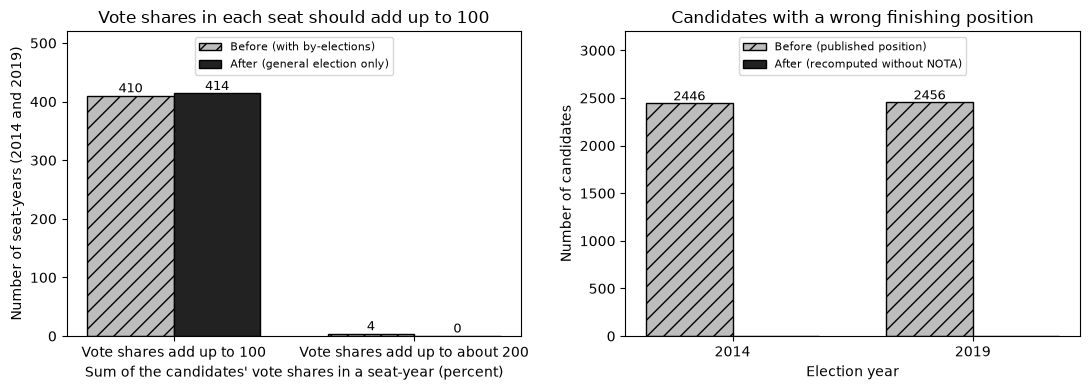

Seat-years with total vote share near 200 before: 4 | after: 0
Wrong positions before: 4902 | after: 0


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# panel 1: seat-years whose vote shares add up to 100 or to about 200, before and after
bad_before = int(((totals_before["total"] - 100).abs() > 0.5).sum())
bad_after = int(((totals_after["total"] - 100).abs() > 0.5).sum())
good_before = len(totals_before) - bad_before
good_after = len(totals_after) - bad_after

x1 = np.arange(2)
axes[0].bar(x1 - 0.18, [good_before, bad_before], width=0.36, color="#BDBDBD", edgecolor="black", hatch="//", label="Before (with by-elections)")
axes[0].bar(x1 + 0.18, [good_after, bad_after], width=0.36, color="#222222", edgecolor="black", label="After (general election only)")
for xi, v in zip(x1 - 0.18, [good_before, bad_before]):
    axes[0].text(xi, v + 6, str(v), ha="center", fontsize=9)
for xi, v in zip(x1 + 0.18, [good_after, bad_after]):
    axes[0].text(xi, v + 6, str(v), ha="center", fontsize=9)
axes[0].set_xticks(x1)
axes[0].set_xticklabels(["Vote shares add up to 100", "Vote shares add up to about 200"])
axes[0].set_title("Vote shares in each seat should add up to 100")
axes[0].set_xlabel("Sum of the candidates' vote shares in a seat-year (percent)")
axes[0].set_ylabel("Number of seat-years (2014 and 2019)")
axes[0].set_ylim(0, 520)
axes[0].legend(loc="upper center", fontsize=8)

# panel 2: wrong positions before and after
labels = ["2014", "2019"]
before_values = [position_fix[2014], position_fix[2019]]
x = np.arange(len(labels))
axes[1].bar(x - 0.18, before_values, width=0.36, color="#BDBDBD", edgecolor="black", hatch="//", label="Before (published position)")
axes[1].bar(x + 0.18, [0, 0], width=0.36, color="#222222", edgecolor="black", label="After (recomputed without NOTA)")
for xi, v in zip(x, before_values):
    axes[1].text(xi - 0.18, v + 30, str(v), ha="center", fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title("Candidates with a wrong finishing position")
axes[1].set_xlabel("Election year")
axes[1].set_ylabel("Number of candidates")
axes[1].set_ylim(0, 3200)
axes[1].legend(loc="upper center", fontsize=8)

plt.tight_layout()
plt.savefig(clean_dir / "figures" / "before_after_cleaning.png", dpi=150)
plt.show()

print("Seat-years with total vote share near 200 before:", bad_before, "| after:", bad_after)
print("Wrong positions before:", sum(before_values), "| after: 0")

**What the figure shows.** Before cleaning, 4 of the 414 seat-years in 2014 and 2019 had a vote share total near 200, and the other 410 added up to 100. After the by-election filter all 414 add up to 100. The published finishing position was wrong for 2,446 candidates in 2014 and 2,456 in 2019 (about two in three real candidates), because NOTA was ranked as a candidate. After recomputing, none is wrong.

### Cleaning log

In [38]:
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
clean_log

,year,step,count_before,count_after,rows_affected,note
0,2014,state names: underscore to space,4010,0,4010,rows with an underscore in State
1,2019,state names: underscore to space,3447,0,3447,rows with an underscore in State
2,2014,keep four states,8843,3868,4975,rows
3,2019,keep four states,8613,3545,5068,rows
4,2024,keep four states,8902,3626,5276,rows
5,2014,drop by-election rows (Poll_No > 0),3868,3844,24,rows; fixes 4 seat-years whose vote shares added up to 200
6,2019,drop by-election rows (Poll_No > 0),3545,3528,17,rows; fixes 4 seat-years whose vote shares added up to 200
7,all,one name per seat,621,207,414,"distinct (State, name) pairs over three years; 207 seats expected"
8,2024,Total Votes: text to number,3626,0,3626,cells stored as text
9,2024,Vote Share: text to number,3626,0,3626,cells stored as text
